# 1. Aprender a leer una serie de tiempo

Una serie de tiempo conserva el orden de los datos. Aquí cada valor es el número de órdenes recibidas en una fecha. Buscamos nivel, tendencia, patrón semanal y episodios extraordinarios.

El diagnóstico se limita a **2017-02-01 a 2017-07-25**, información disponible antes de la primera ventana de selección. Los gráficos de este notebook no observan la prueba para decidir especificaciones.

In [1]:
# La ruta funciona tanto al abrir notebooks/ como desde la raíz del proyecto.
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'sql').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.configuracion import INICIO, FIN, SELECCION, CALIBRACION, PRUEBA, NIVEL, particiones
from src.datos import conectar, consultar, preparar, exportar
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',35)
plt.rcParams.update({'figure.figsize':(12,4),'axes.grid':True,'axes.spines.top':False,'axes.spines.right':False})
(ROOT/'resultados').mkdir(exist_ok=True)
(ROOT/'documentacion/figuras').mkdir(parents=True,exist_ok=True)
con=conectar()  # read_only=True: el análisis no escribe en la base original.
def figura(nombre):
    plt.tight_layout()
    plt.savefig(ROOT/'documentacion/figuras'/f'{nombre}.png',dpi=140,bbox_inches='tight')
    plt.show()

serie,calendario,variables=preparar(con)
y=serie.set_index('fecha').y.asfreq('D')
diagnostico=y.loc[:SELECCION[0]]
print(f'Diagnóstico: {len(diagnostico)} días, hasta {diagnostico.index[-1].date()}.')

Diagnóstico: 175 días, hasta 2017-07-25.


## 1. Separar el tiempo antes de estudiar el modelo

Una **fecha de origen** es el último día observado, al cierre del cual emitimos un pronóstico. El horizonte `h` cuenta cuántos días adelante predecimos.

Las emisiones se hacen cada martes y cubren 28 días. Hay tres funciones distintas: selección elige el modelo; calibración estima márgenes de error; prueba describe su desempeño posterior. Sus fechas objetivo no se mezclan entre etapas.

Dentro de cada etapa hay solapamiento: una fecha puede tener pronósticos emitidos con distintas anticipaciones. Es una simulación operativa válida, pero las predicciones no son observaciones independientes. Los saltos entre los últimos orígenes de una etapa y los primeros de la siguiente evitan que sus objetivos se crucen.

,emisiones,primer_origen,ultimo_origen,objetivos_desde,objetivos_hasta
etapa,,,,,
seleccion,30,2017-07-25,2018-02-13,2017-07-26,2018-03-13
calibracion,12,2018-03-13,2018-05-29,2018-03-14,2018-06-26
prueba,5,2018-06-26,2018-07-24,2018-06-27,2018-08-21


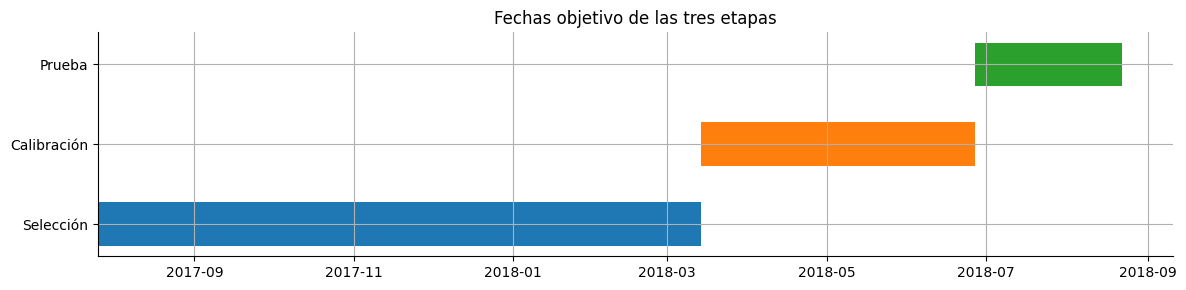

In [2]:
# Las fronteras son parte del diseño, no el resultado de probar modelos.
partes=particiones(); exportar(partes,'particiones')
resumen=partes.groupby('etapa',sort=False).agg(emisiones=('origen','size'),
    primer_origen=('origen','min'),ultimo_origen=('origen','max'),
    objetivos_desde=('desde','min'),objetivos_hasta=('hasta','max'))
display(resumen)
assert partes[partes.etapa.eq('seleccion')].hasta.max()<partes[partes.etapa.eq('calibracion')].desde.min()
assert partes[partes.etapa.eq('calibracion')].hasta.max()<partes[partes.etapa.eq('prueba')].desde.min()
fig,ax=plt.subplots(figsize=(12,3))
for i,etapa in enumerate(['seleccion','calibracion','prueba']):
    g=partes[partes.etapa.eq(etapa)]
    ax.barh(i,(g.hasta.max()-g.desde.min()).days+1,left=g.desde.min(),height=.55,label=etapa)
ax.set_yticks(range(3),['Selección','Calibración','Prueba']); ax.xaxis_date()
ax.set_title('Fechas objetivo de las tres etapas'); figura('protocolo_temporal')

## 2. Nivel, tendencia y patrón semanal

El **nivel** es la magnitud habitual de pedidos; la **tendencia** describe su evolución lenta. Una media móvil de 28 días suaviza fluctuaciones y usa, en esta consulta, solo el día actual y los 27 anteriores.

El patrón por día de semana compara lunes con lunes, martes con martes, etc. Las medias son descriptivas: un lunes con un evento extraordinario puede elevarlas. Por eso también mostramos medianas.

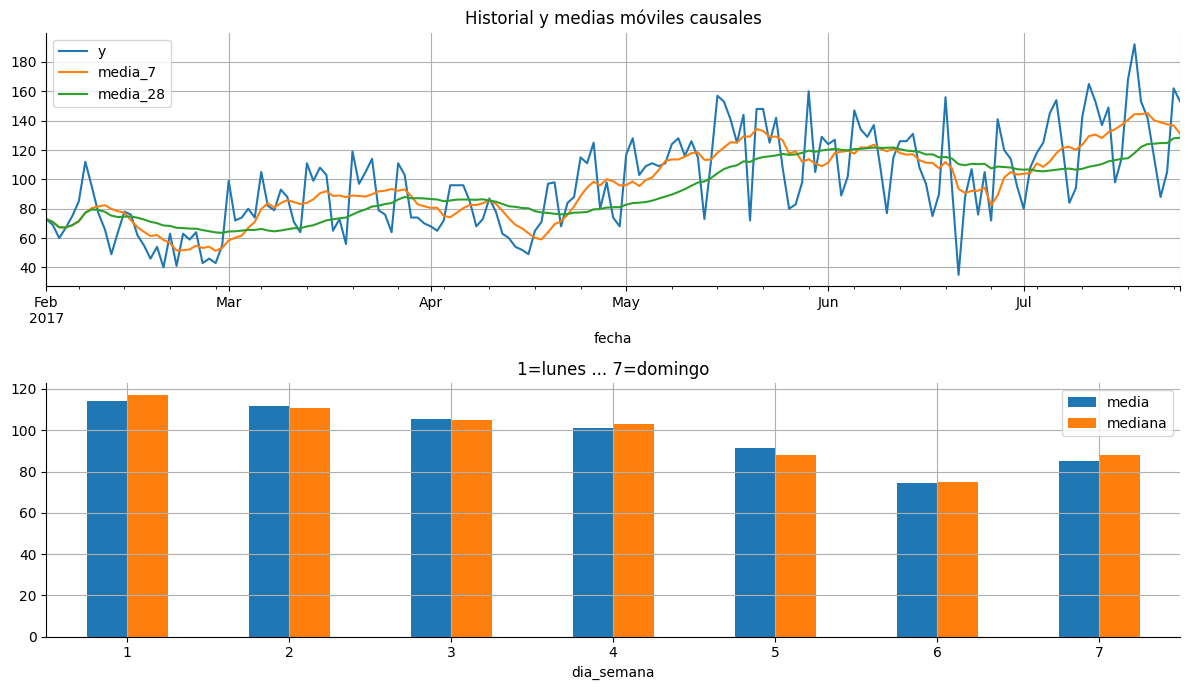

,dia_semana,dias,media,mediana
0,1,25,114.08,117.0
1,2,25,111.60,111.0
2,3,25,105.44,105.0
3,4,25,100.88,103.0
4,5,25,91.44,88.0
5,6,25,74.52,75.0
6,7,25,85.12,88.0


En este historial, el día 1 presenta la mayor media. No prueba una relación causal.


In [3]:
# Tanto las ventanas como la agrupación por día de semana se realizan en SQL.
moviles=consultar(con,'diagnostico.sql',[str(SELECCION[0].date())])
patron=consultar(con,'patron_semanal.sql',[str(SELECCION[0].date())])
exportar(moviles,'diagnostico_inicial'); exportar(patron,'patron_semanal')
fig,ax=plt.subplots(2,1,figsize=(12,7))
moviles.plot(x='fecha',y=['y','media_7','media_28'],ax=ax[0],title='Historial y medias móviles causales')
patron.plot.bar(x='dia_semana',y=['media','mediana'],ax=ax[1],rot=0,title='1=lunes ... 7=domingo')
figura('patrones_iniciales'); display(patron)
mayor=int(patron.loc[patron.media.idxmax(),'dia_semana'])
print(f'En este historial, el día {mayor} presenta la mayor media. No prueba una relación causal.')

## 3. Descomposición STL

STL representa la observación como tendencia + componente estacional + residuo. Se fija período 7 porque una semana tiene siete días. La opción robusta reduce la influencia de picos al estimar los componentes.

El residuo es lo que esta descomposición no explica. No equivale al error de un pronóstico futuro. STL puede usar vecinos posteriores dentro del tramo analizado; por ello sus componentes sirven aquí para **describir**, no como variables del modelo.

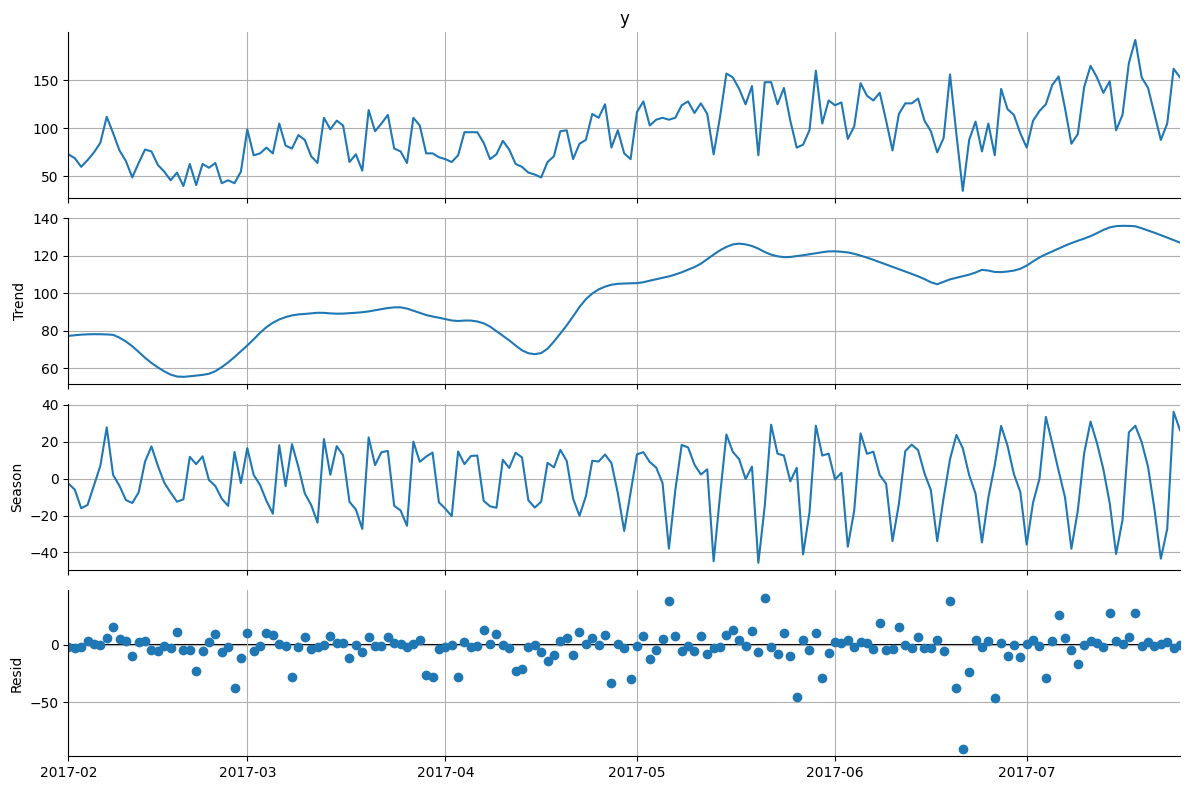

In [4]:
# Descomponemos solo el historial inicial; no usamos STL como predictor.
from statsmodels.tsa.seasonal import STL
stl=STL(diagnostico,period=7,robust=True).fit()
fig=stl.plot(); fig.set_size_inches(12,8)
figura('stl_inicial')

## 4. ACF y PACF: relaciones con el pasado

ACF mide la asociación del valor actual con valores de hace 1, 2, ... días. PACF estima la asociación adicional de un rezago después de controlar los rezagos intermedios. La persistencia y los picos cerca de múltiplos de 7 ayudan a reconocer estructura temporal.

Una tendencia puede producir autocorrelación alta aunque no exista una relación estable. Estas gráficas orientan el análisis, pero no identifican de forma infalible el orden de ARIMA.

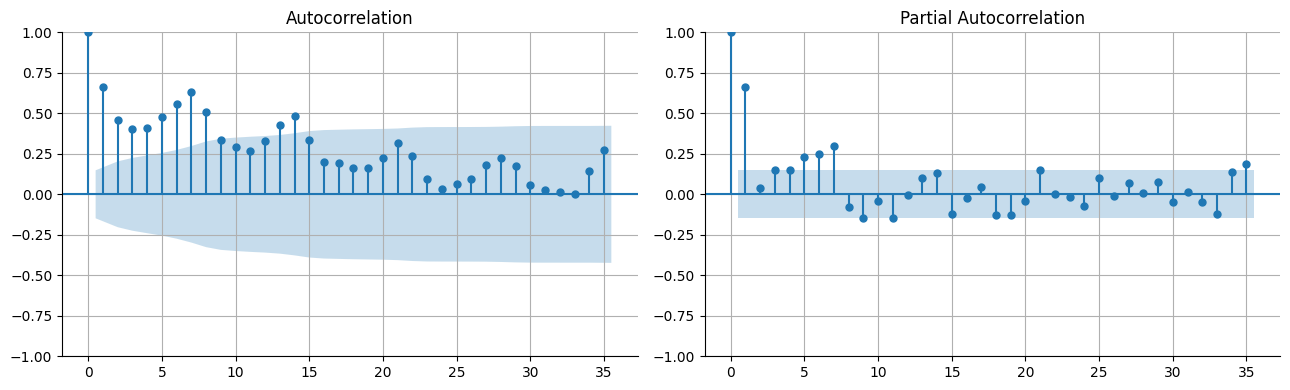

In [5]:
# Las barras describen dependencia del pasado y requieren interpretación.
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
fig,ax=plt.subplots(1,2,figsize=(13,4))
plot_acf(diagnostico,lags=35,ax=ax[0]); plot_pacf(diagnostico,lags=35,method='ywm',ax=ax[1])
figura('acf_pacf_inicial')

## 5. ADF y KPSS: interpretar hipótesis opuestas

- ADF parte de la hipótesis de raíz unitaria. Un p pequeño aporta evidencia contra ella.
- KPSS parte de estacionariedad alrededor de un nivel. Un p pequeño aporta evidencia contra ella.

Comparamos nivel, primera diferencia y diferencia semanal. Diferenciar significa restar el pasado: `y(t)-y(t-1)` o `y(t)-y(t-7)`. Los resultados dependen del tramo, la especificación y el tamaño muestral. No prueban que todos los períodos futuros tengan la misma distribución ni eligen automáticamente un modelo.

In [6]:
import warnings
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
filas=[]
for nombre,s in [('nivel',diagnostico),('diferencia_1',diagnostico.diff().dropna()),
                 ('diferencia_7',diagnostico.diff(7).dropna())]:
    adf=adfuller(s,autolag='AIC',result_object=False)
    # Capturamos avisos para EXPLICAR límites de la tabla, no para ocultarlos.
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        kp=kpss(s,regression='c',nlags='auto',result_object=False)
    limite=f'{kp[1]:.4f}'
    for aviso in avisos:
        if issubclass(aviso.category,InterpolationWarning):
            limite=('<= ' if 'smaller' in str(aviso.message) else '>= ')+f'{kp[1]:.2f}'
        else:
            warnings.warn(str(aviso.message),aviso.category)
    filas.append(dict(serie=nombre,ADF_p=adf[1],KPSS_p_tabla=kp[1],KPSS_limite=limite,
        ADF_lectura='Rechaza raíz unitaria' if adf[1]<.05 else 'No rechaza raíz unitaria',
        KPSS_lectura='Rechaza estacionariedad' if kp[1]<.05 else 'No rechaza estacionariedad'))
pruebas=pd.DataFrame(filas); display(pruebas); exportar(pruebas,'estacionariedad')
print('Los símbolos <= o >= indican límites tabulados del p-valor de KPSS.')

,serie,ADF_p,KPSS_p_tabla,KPSS_limite,ADF_lectura,KPSS_lectura
0,nivel,0.710938,0.010000,<= 0.01,No rechaza raíz unitaria,Rechaza estacionariedad
1,diferencia_1,0.000005,0.041667,0.0417,Rechaza raíz unitaria,Rechaza estacionariedad
2,diferencia_7,0.001762,0.100000,>= 0.10,Rechaza raíz unitaria,No rechaza estacionariedad


Los símbolos <= o >= indican límites tabulados del p-valor de KPSS.


## 6. Decisiones para modelar

Compararemos una referencia constante, una referencia semanal, ETS con tendencia amortiguada, SARIMAX con calendario y cuatro variantes de LightGBM.

SARIMAX usará errores ARIMA(1,1,1) sobre `log1p(y)` y seis indicadores de día de semana. En esta especificación la repetición semanal está en los regresores; no se impone diferencia semanal adicional. Es un candidato parsimonioso fijado de antemano, no una afirmación de que sea el único orden correcto.

Los eventos conocidos por calendario incluyen festivos nacionales brasileños, Black Friday, cuatro días posteriores y fin de año. No se afirma que el calendario cubra todos los festivos locales o campañas. La huelga de mayo de 2018 se conserva y se analiza como episodio histórico; su aparición futura no se proporciona al modelo como si se conociera de antemano.

**Para explicar en clase:** el calendario futuro es información disponible; el número de compras futuras no lo es. Esa distinción permite usar el día de semana de un objetivo sin cometer fuga de información.

## 7. Ver cómo se calculan las fechas especiales

Al ejecutar `preparar(con)` al inicio del notebook, [la función de datos](../src/datos.py) obtiene los festivos nacionales de Brasil con `holidays`. Después, `sql/calendario.sql` crea una fila por fecha y cuatro columnas binarias: `festivo`, `black_friday`, `post_black_friday` y `fin_anio`. **1 significa que se cumple la regla de calendario; 0, que no se cumple.**

Black Friday es el viernes siguiente al cuarto jueves de noviembre. `post_black_friday` marca sus cuatro días posteriores. `fin_anio` marca el 24–31 de diciembre y el 1 de enero. Una fecha puede tener más de un indicador: Navidad es festivo y también pertenece al período de fin de año.

La tabla siguiente muestra el resultado real del cálculo, incluidos un día de huelga y un festivo futuro respecto al último día de compras seleccionado. `pedidos_observados` se añade **solo para entender el ejemplo**; no se utiliza para crear los indicadores. En septiembre de 2018, esa columna está vacía mientras que el festivo ya se conoce.

In [7]:
# Mostrar fechas concretas calculadas por SQL y sus compras, cuando existen.
calendario_ejemplos=consultar(con,'ejemplos_calendario.sql')
display(calendario_ejemplos)
exportar(calendario_ejemplos,'ejemplos_calendario')
# Resumimos cuántos días activa cada indicador; pueden coincidir en una fecha.
resumen_calendario=consultar(con,'resumen_calendario.sql')
display(resumen_calendario)
exportar(resumen_calendario,'resumen_calendario')
print('Black Friday 2017 marca 1; el día siguiente marca post_black_friday=1.')
print('El 21/05/2018 no recibe un indicador de huelga futura.')

,fecha,dia_semana,festivo,black_friday,post_black_friday,fin_anio,pedidos_observados
0,2017-11-24,5,0,1,0,0,1176
1,2017-11-25,6,0,0,1,0,499
2,2017-12-24,7,0,0,0,1,59
3,2017-12-25,1,1,0,0,1,90
4,2018-01-01,1,1,0,0,1,74
5,2018-05-21,1,0,0,0,0,206
6,2018-09-07,5,1,0,0,0,<NA>


,anio,dias_calendario,dias_festivos_nacionales,dias_black_friday,dias_post_black_friday,dias_fin_anio
0,2017,334,8.0,1.0,4.0,8.0
1,2018,261,5.0,0.0,0.0,1.0


Black Friday 2017 marca 1; el día siguiente marca post_black_friday=1.
El 21/05/2018 no recibe un indicador de huelga futura.


In [8]:
# Cerramos el acceso de solo lectura; el siguiente notebook es autónomo.
con.close()
print('Continúa con 02_modelado_y_pronostico.ipynb.')

Continúa con 02_modelado_y_pronostico.ipynb.
